In [2]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
#Plot spectres 
from scipy import signal
from scipy import fft
import netCDF4


## Annex 3-B - Overshootings caused by bi-laplacian diffusion

In [3]:
rep = '/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/canal_test/EXP00/'

In [4]:
lap_test_ = xr.open_dataset(rep+'CANAL_saltblock_test_all_grid.nc')
lap_test = lap_test_.soce
blp_test_ = xr.open_dataset(rep+'CANAL_saltblock_blp_test_all_grid.nc')
blp_test = blp_test_.soce

In [5]:
domx = 1020
domy = 1020
dx = 20
dy = 20
sx = 250//dx//2
sy = 250//dy//2

x0 = domx//dx//2
y0 = domy//dy//2

t0 = 900*24*3600
dt = 900*24*3600
v = 0.5

salt_ref = np.ones(shape = (domy//dy, domx//dx))*30 
salt_ref[y0-sy:y0+sy+1, x0 - sx: x0+sx +1] = 35

In [13]:
ref = salt_ref[:,25]

/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_43864/340474429.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Snapshot of the salinity field for a bi-laplacian diffusion for a square wave initial distribution')

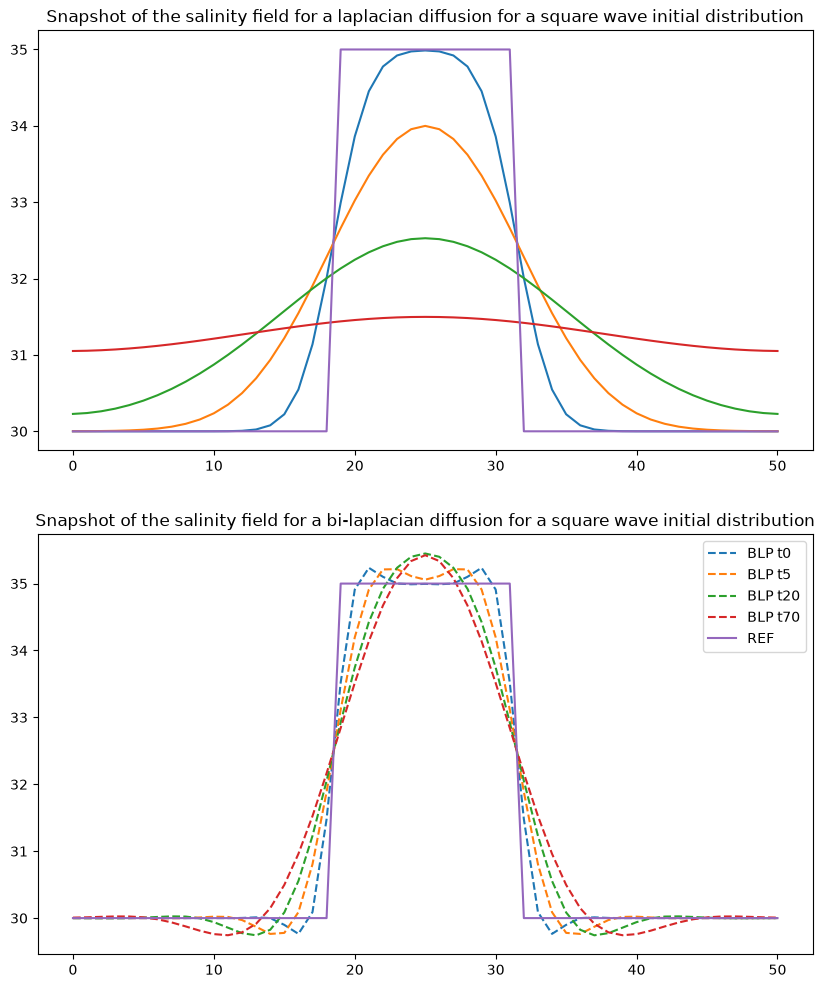

In [70]:

lap_test_t0=lap_test.isel(y_grid_T= 25, deptht = 0, time_counter=0)
lap_test_t1=lap_test.isel(y_grid_T= 25, deptht = 0,time_counter=5)
lap_test_t2=lap_test.isel(y_grid_T= 25, deptht = 0, time_counter=20)
lap_test_t3=lap_test.isel(y_grid_T= 25, deptht = 0, time_counter=70)


blp_test_t0=blp_test.isel(y_grid_T= 25, deptht = 0, time_counter=0)
blp_test_t1=blp_test.isel(y_grid_T= 25, deptht = 0, time_counter=5)
blp_test_t2=blp_test.isel(y_grid_T= 25, deptht = 0, time_counter=20)
blp_test_t3=blp_test.isel(y_grid_T= 25, deptht = 0, time_counter=70)


X = np.arange(len(lap_test_t0))

fig, ax = plt.subplots(2, 1, figsize = (10, 12))

ax[0].plot(X, lap_test_t0, '-',label = 'LAP t0')
ax[0].plot(X, lap_test_t1, '-', label = 'LAP t5')
ax[0].plot(X, lap_test_t2, '-', label = 'LAP t20')
ax[0].plot(X, lap_test_t3, '-', label = 'LAP t70')

ax[0].plot(X, ref, '-', label = 'REF')


plt.legend()

ax[0].set_title('Snapshot of the salinity field for a laplacian diffusion for a square wave initial distribution')


ax[1].plot(X, blp_test_t0, '--',label = 'BLP t0')
ax[1].plot(X, blp_test_t1, '--', label = 'BLP t5')
ax[1].plot(X, blp_test_t2, '--', label = 'BLP t20')
ax[1].plot(X, blp_test_t3, '--', label = 'BLP t70')

ax[1].plot(X, ref, '-',label = 'REF')

plt.legend()
ax[1].set_title('Snapshot of the salinity field for a bi-laplacian diffusion for a square wave initial distribution')



Overshoot/undershoot for bilaplacian and not for laplacian.

In [72]:
fe = 20       # Fréquence d'échantillonnage (en Hz)
dx = 1.0 / fe   

# 2. Calcul de la FFT du signal creneau
fft_valeurs = np.fft.fft(ref)
fft_frequences = np.fft.fftfreq(len(ref), dt)

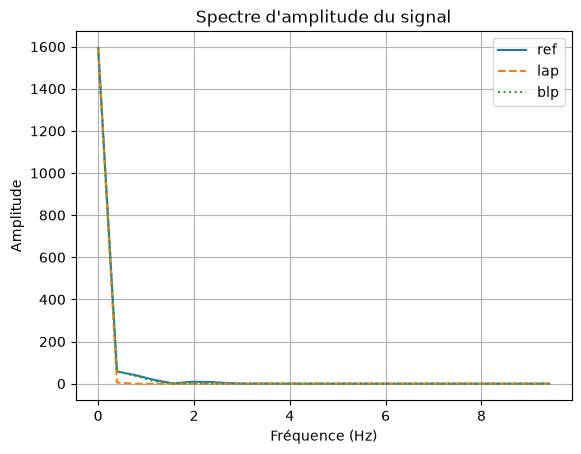

In [93]:
plt.figure()
plt.plot(fft_frequences[:len(ref)//2], np.abs(fft_valeurs[:len(ref)//2]), label ='ref')

# 2. Calcul de la FFT du signal creneau
lap_fft = lap_test.isel(y_grid_T= 25, deptht = 0, time_counter=70)
fft_valeurs = np.fft.fft(lap_fft)
fft_frequences = np.fft.fftfreq(len(lap_fft), dt)

plt.plot(fft_frequences[:len(lap_fft)//2], np.abs(fft_valeurs[:len(lap_fft)//2]), '--' , label ='lap')

# 2. Calcul de la FFT du signal creneau
blp_fft = blp_test.isel(y_grid_T= 25, deptht = 0, time_counter=70)
fft_valeurs = np.fft.fft(blp_fft)
fft_frequences = np.fft.fftfreq(len(blp_fft), dt)


plt.plot(fft_frequences[:len(blp_fft)//2], np.abs(fft_valeurs[:len(blp_fft)//2]), ':' , label= 'blp')
plt.legend()
plt.title("Spectre d'amplitude du signal")
plt.xlabel("Fréquence (Hz)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

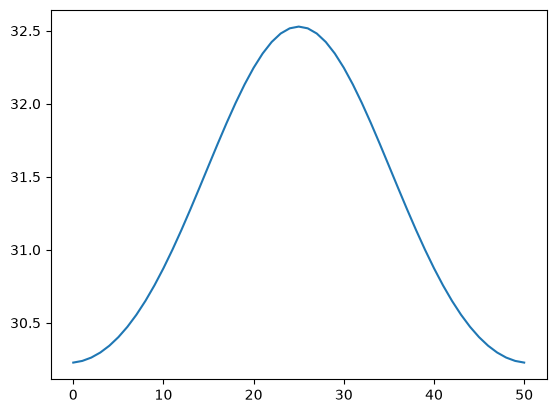

In [94]:
inverse = np.fft.ifft(fft_valeurs_1)
plt.plot(inverse)

/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_43864/2267857741.py:1: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 51, using nperseg = 51
  f_ref, psd_ref = signal.welch(ref, fe, window = 'tukey')
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_43864/2267857741.py:2: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 51, using nperseg = 51
  f_blp, psd_blp = signal.welch(blp_fft, fe, window = 'tukey')
/var/folders/rt/k5yxzgzd793fcl03j9vc4cnm0000gs/T/ipykernel_43864/2267857741.py:3: UserWarning: nperseg=256 is greater than signal length max(len(x), len(y)) = 51, using nperseg = 51
  f_lap, psd_lap = signal.welch(lap_fft, fe, window = 'tukey')


Text(0.5, 1.0, 'Power Spectral Distribution')

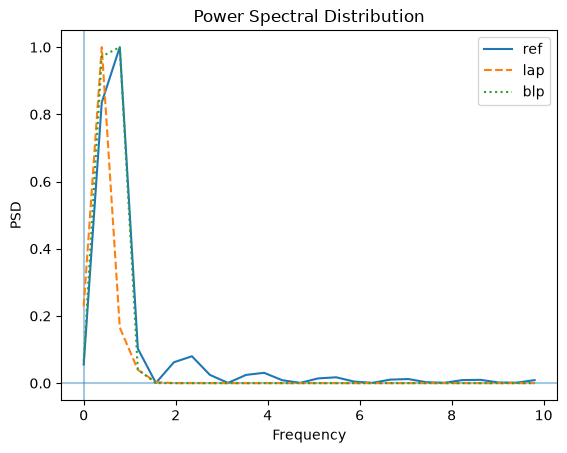

In [95]:

f_ref, psd_ref = signal.welch(ref, fe, window = 'tukey')
f_blp, psd_blp = signal.welch(blp_fft, fe, window = 'tukey')
f_lap, psd_lap = signal.welch(lap_fft, fe, window = 'tukey')

plt.axhline(alpha = 0.4)
plt.axvline(alpha = 0.4)

plt.plot(f_ref, psd_ref/psd_ref.max(), label = 'ref')
plt.plot(f_lap, psd_lap/psd_lap.max(), '--', label = 'lap')
plt.plot(f_blp, psd_blp/psd_blp.max(), ':', label = 'blp')

#plt.loglog(f[5:20] , [k**(-5/3)/1000000000000 for k in f[5:20]], label = 'k^-5/3')
#plt.loglog(f[20:], [k**(-3)/100000000000000 for k in f[20:]], label = 'k^-3')
plt.legend()
plt.xlabel('Frequency')
plt.ylabel('PSD')
plt.title('Power Spectral Distribution')